In [ ]:
!pip install -q tensorflow opencv-python seaborn kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"rashidamir0414","key":"42926dee8df18889f360248199c05d5d"}'}

In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d emmarex/plantdisease
!unzip -q plantdisease.zip

Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:22<00:00, 31.3MB/s]



In [ ]:
import os
import numpy as np
import cv2
import shutil
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

In [ ]:
DATASET_PATH = "PlantVillage"
TARGET_DIR = "dataset"

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(TARGET_DIR)

folders = os.listdir(DATASET_PATH)
selected_classes = [f for f in folders if "Tomato" in f][:3]

print("Selected Classes:", selected_classes)

for folder in selected_classes:
    src = os.path.join(DATASET_PATH, folder)
    dst = os.path.join(TARGET_DIR, folder)
    os.makedirs(dst)

    for file in os.listdir(src)[:800]:
        shutil.copy(os.path.join(src, file), dst)

print("✅ Dataset ready!")

Selected Classes: ['Tomato_healthy', 'Tomato_Leaf_Mold', 'Tomato_Bacterial_spot']
✅ Dataset ready!


In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=25,
    zoom_range=0.3,
    horizontal_flip=True
)

train_data = datagen.flow_from_directory(
    TARGET_DIR,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    TARGET_DIR,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

class_names = list(train_data.class_indices.keys())
print("Classes:", class_names)

Found 1920 images belonging to 3 classes.
Found 480 images belonging to 3 classes.
Classes: ['Tomato_Bacterial_spot', 'Tomato_Leaf_Mold', 'Tomato_healthy']


In [ ]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

for layer in base_model.layers[:-30]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(len(class_names), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,586,691 (9.87 MB)

 Trainable params: 1,855,107 (7.08 MB)

 Non-trainable params: 731,584 (2.79 MB)

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 178s 3s/step - accuracy: 0.8604 - loss: 0.3551 - val_accuracy: 0.9604 - val_loss: 0.1297
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.9724 - loss: 0.0833 - val_accuracy: 0.9771 - val_loss: 0.0741
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 161s 3s/step - accuracy: 0.9844 - loss: 0.0499 - val_accuracy: 0.9604 - val_loss: 0.1167
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 187s 3s/step - accuracy: 0.9891 - loss: 0.0344 - val_accuracy: 0.9854 - val_loss: 0.0361
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.9875 - loss: 0.0300 - val_accuracy: 0.9896 - val_loss: 0.0341
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9948 - loss: 0.0170 - val_accuracy: 0.9875 - val_loss: 0.0386
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 174s 3s/step - accuracy: 0.9937 - loss: 0.0220 - val_accuracy: 0.9729 - val_loss: 0.0904
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.9917 - loss: 0.0265 - val_accuracy: 0.9812 - v

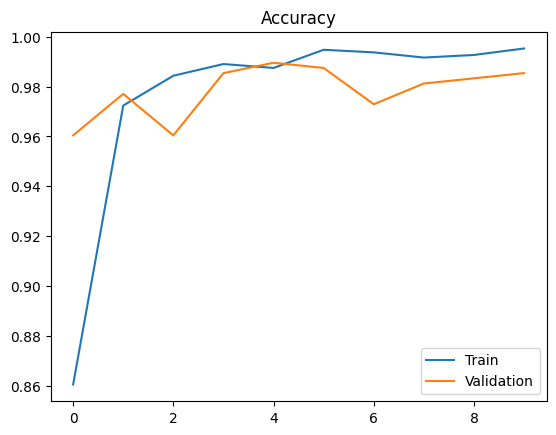

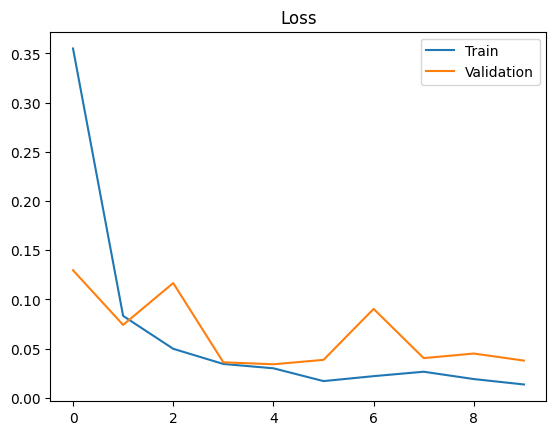

In [ ]:
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.legend(["Train","Validation"])
plt.show()

plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.legend(["Train","Validation"])
plt.show()

15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step


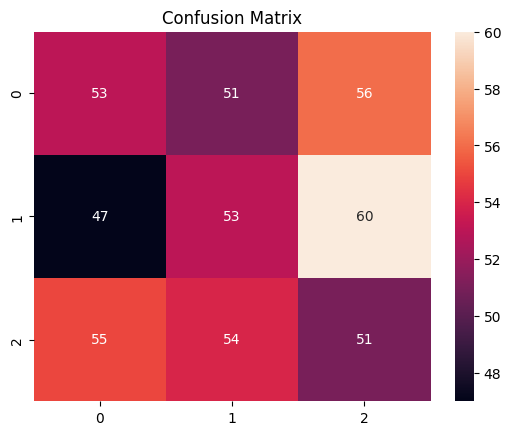

                       precision    recall  f1-score   support

Tomato_Bacterial_spot       0.34      0.33      0.34       160
     Tomato_Leaf_Mold       0.34      0.33      0.33       160
       Tomato_healthy       0.31      0.32      0.31       160

             accuracy                           0.33       480
            macro avg       0.33      0.33      0.33       480
         weighted avg       0.33      0.33      0.33       480



In [ ]:
y_true = val_data.classes
y_pred = model.predict(val_data)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure()
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred_classes, target_names=class_names))

In [ ]:
model.save("plant_model.keras")
print("✅ Model saved!")

✅ Model saved!


In [ ]:
def predict_image(image_path):
    img = cv2.imread(image_path)
    img = cv2.resize(img, (224,224))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)

    pred = model.predict(img)
    label = class_names[np.argmax(pred)]
    confidence = np.max(pred)*100

    print("Prediction:", label)
    print("Confidence:", f"{confidence:.2f}%")

# test using dataset image
sample = os.path.join(DATASET_PATH, selected_classes[0],
                      os.listdir(os.path.join(DATASET_PATH, selected_classes[0]))[0])

predict_image(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Prediction: Tomato_healthy
Confidence: 100.00%
